# Flight Price Prediction: HistGradientBoosting + RandomForest + ExtraTrees

In [ ]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import nnls
from sklearn.ensemble import (ExtraTreesRegressor,
                              HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme()
pd.set_option("display.max_columns", None)

# Find the project folder (contains MT2026046/data/flight_price)
BASE = None
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "MT2026046" / "data" / "flight_price").exists():
        BASE = folder / "MT2026046"
        break
if BASE is None:
    raise FileNotFoundError("Run this notebook from inside the repository.")
DATA = BASE / "data" / "flight_price"
FIGURES = BASE / "figures"
SUBMISSIONS = BASE / "submissions"
RESULTS = BASE / "results"
for folder in (FIGURES, SUBMISSIONS, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)
print("working folder:", BASE)

SEED = 42


def show_table(frame):
    """Print a table as plain text so it renders the same in every viewer."""
    print(frame.to_string())

working folder: C:\Users\Aradhya\Desktop\ml_project\nb\MT2026046


## 1. Load data

In [2]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")

# Combine so encodings and counts are consistent across train and test
train["is_train"] = 1
test["is_train"] = 0
test["price"] = np.nan
df = pd.concat([train, test], ignore_index=True)

print("Train shape:", train.shape, "| Test shape:", test.shape)

Train shape: (18076, 13) | Test shape: (4520, 13)


## 2. Data Preprocessing

The flight code is split into a number and a prefix. The stops text are converted to an ordinal number. The classes are converted to a 0/1 flag, and two additional columns are added.

In [3]:
# flight code like "AI 505" -> number 505 and prefix "AI"
df["flight_num"] = df["flight"].str.extract(r"(\d+)").astype(float)
df["flight_prefix"] = df["flight"].str.extract(r"^([A-Z0-9]+)\s")

# stops text -> number
df["stops_n"] = df["stops"].map({"zero": 0, "one": 1, "two_or_more": 2})

# class -> 0/1
df["is_business"] = (df["flight_class"] == "Business").astype(int)

# route and city pair
df["route"] = df["source_city"] + ">" + df["destination_city"]
df["city_pair"] = ["|".join(sorted(p)) for p in zip(df["source_city"], df["destination_city"])]
show_table(df.head(3))

      id    airline   flight source_city departure_time stops arrival_time destination_city flight_class  duration  days_left  price  is_train  flight_num flight_prefix  stops_n  is_business                    route                city_pair
0   2856  Southwest  WN 3596    San Jose  Early_Morning  zero      Morning      Los Angeles      Economy      1.33          5  315.0         1      3596.0            WN        0            0     San Jose>Los Angeles     Los Angeles|San Jose
1  21812  Southwest  WN 1307    San Jose        Evening  zero      Evening        San Diego      Economy      1.58         40  149.0         1      1307.0            WN        0            0       San Jose>San Diego       San Diego|San Jose
2    476     United  UA 1763   San Diego      Afternoon  zero    Afternoon    San Francisco      Economy      1.77          2  129.0         1      1763.0            UA        0            0  San Diego>San Francisco  San Diego|San Francisco

## 3. Feature engineering

In [4]:
# 3a. Count features: how often a combination appears (no price used)
df["key_flight_class"] = df["flight"] + "|" + df["flight_class"]
df["key_route_air_class_stops"] = (df["route"] + "|" + df["airline"] + "|"
                                   + df["flight_class"] + "|" + df["stops"])
df["key_flight_class_day"] = df["key_flight_class"] + "|" + df["days_left"].astype(str)
df["key_route_day"] = df["key_route_air_class_stops"] + "|" + df["days_left"].astype(str)

for col in ["flight", "key_flight_class", "key_route_air_class_stops",
            "key_flight_class_day", "key_route_day"]:
    df["count_" + col] = df.groupby(col)[col].transform("count")

# 3b. Duration features
df["duration_extra"] = df["duration"] - df.groupby(["route", "stops_n"])["duration"].transform("min")
df["duration_per_stop"] = df["duration"] / (df["stops_n"] + 1)
df["duration_flight_median"] = df.groupby("flight")["duration"].transform("median")

# 3c. Encode text columns as integer codes
text_cols = ["airline", "source_city", "destination_city", "departure_time",
             "arrival_time", "flight_prefix", "route", "city_pair"]
for col in text_cols:
    df[col + "_code"] = df[col].astype("category").cat.codes
print("columns after engineering:", len(df.columns))

columns after engineering: 39


## 4. Select features and split back into train / test

The model uses 21 features: eight numeric, eight integer codes and five counts.

In [5]:
features = (["duration", "days_left", "flight_num", "stops_n", "is_business",
             "duration_extra", "duration_per_stop", "duration_flight_median"]
            + [c + "_code" for c in text_cols]
            + [c for c in df.columns if c.startswith("count_")])

train_df = df[df["is_train"] == 1].reset_index(drop=True)
test_df = df[df["is_train"] == 0].reset_index(drop=True)

X = train_df[features].fillna(-1)
y = train_df["price"].values
X_test = test_df[features].fillna(-1)
print("features:", len(features))

features: 21


## 5. Models

HistGradientBoosting, RandomForest and ExtraTrees. The metric helpers print RMSE and R2.

In [6]:
def build_models():
    return {
        "hgb": HistGradientBoostingRegressor(learning_rate=0.05, max_iter=500,
                                             max_leaf_nodes=63, max_depth=8,
                                             min_samples_leaf=20, random_state=0),
        "rf": RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                    max_features=0.5, n_jobs=-1, random_state=0),
        "et": ExtraTreesRegressor(n_estimators=300, min_samples_leaf=2,
                                  max_features=0.7, n_jobs=-1, random_state=0),
    }


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


def r2(a, b):
    return float(1 - ((a - b) ** 2).sum() / ((a - a.mean()) ** 2).sum())

## 6. Cross-validation (5-fold)

Out-of-fold predictions for each model.

In [7]:
names = list(build_models().keys())
oof = {n: np.zeros(len(X)) for n in names}   # out-of-fold predictions

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (tr_idx, val_idx) in enumerate(kf.split(X), start=1):
    t0 = time.time()
    models = build_models()
    for n in names:
        models[n].fit(X.iloc[tr_idx], y[tr_idx])
        oof[n][val_idx] = models[n].predict(X.iloc[val_idx])
    print(f"fold {fold}/5 done ({time.time() - t0:.0f}s)")

print("\nCross-validation results")
cv_rows = []
for n in names:
    cv_rows.append({"model": n, "rmse": round(rmse(y, oof[n]), 2), "r2": round(r2(y, oof[n]), 4)})
cv_table = pd.DataFrame(cv_rows)
show_table(cv_table)

fold 1/5 done (4s)


fold 2/5 done (5s)


fold 3/5 done (6s)


fold 4/5 done (6s)


fold 5/5 done (6s)

Cross-validation results
  model    rmse      r2
0   hgb  122.32  0.6963
1    rf  122.85  0.6937
2    et  124.05  0.6876


## 7. Combination / Blend of the 3 models

Blend weights: {'hgb': 0.536, 'rf': 0.298, 'et': 0.166}
  BLEND RMSE=120.82  R2=0.7037
   model    rmse      r2
0    hgb  122.32  0.6963
1     rf  122.85  0.6937
2     et  124.05  0.6876
3  blend  120.82  0.7037


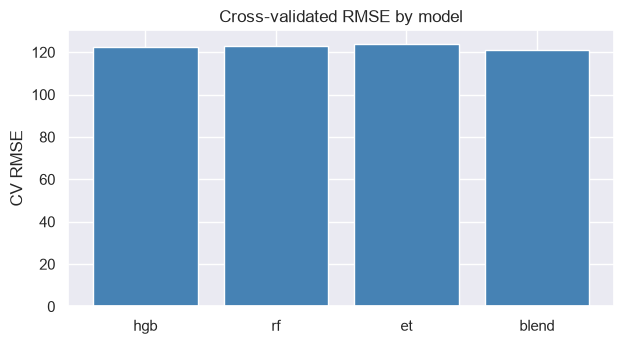

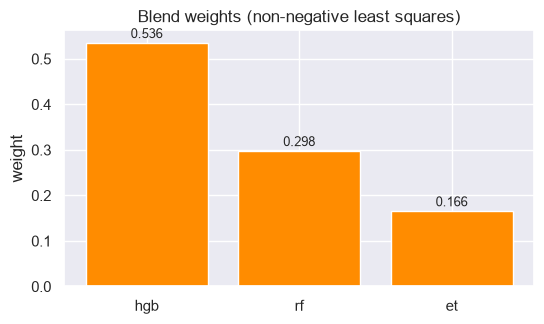

In [8]:
oof_matrix = np.column_stack([oof[n] for n in names])
weights, _ = nnls(oof_matrix, y)
weights = weights / weights.sum()

blend = oof_matrix @ weights
print("Blend weights:", dict(zip(names, [float(round(w, 3)) for w in weights])))
print(f"  BLEND RMSE={rmse(y, blend):.2f}  R2={r2(y, blend):.4f}")

summary = cv_table.copy()
summary.loc[len(summary)] = {"model": "blend", "rmse": round(rmse(y, blend), 2), "r2": round(r2(y, blend), 4)}
show_table(summary)
summary.to_csv(RESULTS / "flight_blend_results.csv", index=False)

fig, axis = plt.subplots(figsize=(6.4, 3.6))
axis.bar(summary["model"], summary["rmse"], color="steelblue")
axis.set_ylabel("CV RMSE")
axis.set_title("Cross-validated RMSE by model")
fig.tight_layout()
fig.savefig(FIGURES / "blend_model_comparison.png", dpi=150)
plt.show()

fig, axis = plt.subplots(figsize=(5.6, 3.4))
axis.bar(names, weights, color="darkorange")
for i, w in enumerate(weights):
    axis.text(i, w + 0.01, f"{w:.3f}", ha="center", fontsize=9)
axis.set_ylabel("weight")
axis.set_title("Blend weights (non-negative least squares)")
fig.tight_layout()
fig.savefig(FIGURES / "blend_weights.png", dpi=150)
plt.show()

## 8. Final training and test predictions

In [9]:
final_models = build_models()
test_preds = []
for n in names:
    final_models[n].fit(X, y)
    test_preds.append(final_models[n].predict(X_test))

final_pred = np.column_stack(test_preds) @ weights
final_pred = np.clip(final_pred, 0, None)   # no negative prices
print("test predictions ready:", final_pred.shape)

test predictions ready: (4520,)


## 9. Diagnostics

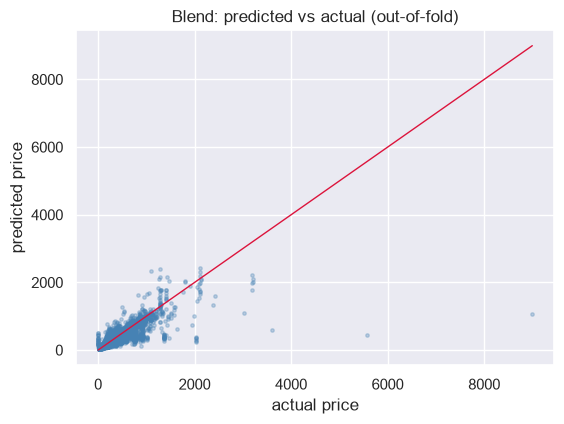

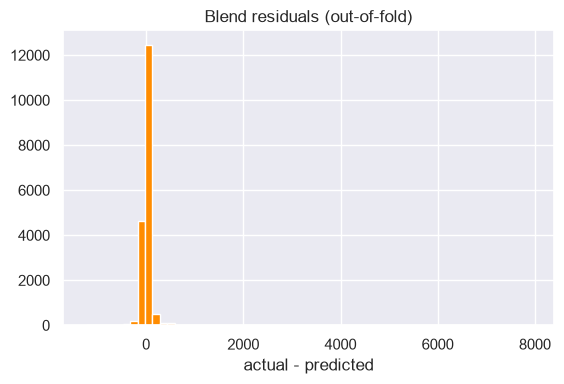

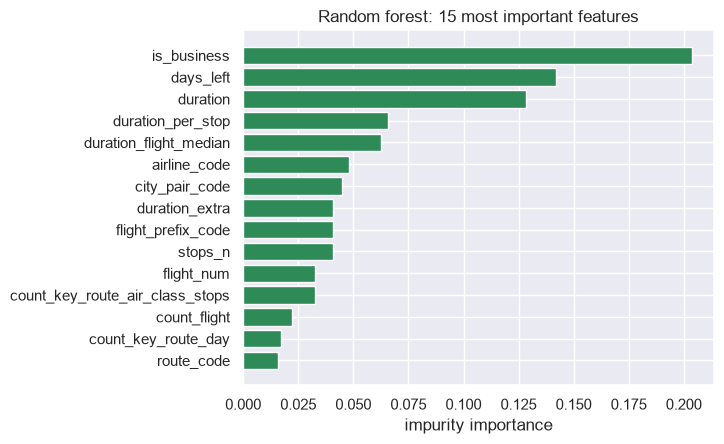

In [10]:
fig, axis = plt.subplots(figsize=(5.8, 4.4))
axis.scatter(y, blend, s=6, alpha=0.3, color="steelblue")
upper = float(max(y.max(), blend.max()))
axis.plot([0, upper], [0, upper], color="crimson", lw=1)
axis.set_xlabel("actual price")
axis.set_ylabel("predicted price")
axis.set_title("Blend: predicted vs actual (out-of-fold)")
fig.tight_layout()
fig.savefig(FIGURES / "blend_pred_vs_actual.png", dpi=150)
plt.show()

fig, axis = plt.subplots(figsize=(5.8, 4.0))
axis.hist(y - blend, bins=60, color="darkorange")
axis.set_xlabel("actual - predicted")
axis.set_title("Blend residuals (out-of-fold)")
fig.tight_layout()
fig.savefig(FIGURES / "blend_residuals.png", dpi=150)
plt.show()

importances = pd.Series(final_models["rf"].feature_importances_, index=features)
importances = importances.sort_values(ascending=False).head(15)
fig, axis = plt.subplots(figsize=(7.4, 4.6))
axis.barh(importances.index[::-1], importances.values[::-1], color="seagreen")
axis.set_xlabel("impurity importance")
axis.set_title("Random forest: 15 most important features")
fig.tight_layout()
fig.savefig(FIGURES / "rf_feature_importance.png", dpi=150)
plt.show()

## 10. Save submission

Format: id and predicted price.

In [11]:
submission = pd.DataFrame({"id": test_df["id"], "price": final_pred})
path = SUBMISSIONS / "submission.csv"
submission.to_csv(path, index=False)
print(f"Saved {path} ({len(submission)} rows)")
show_table(submission.head())

Saved C:\Users\Aradhya\Desktop\ml_project\nb\MT2026046\submissions\submission.csv (4520 rows)
      id       price
0  18395   76.150601
1  11771  169.736540
2  22326  376.150485
3  18332  131.439230
4  11021  550.651723
